# NB03 · Credit cycle

**Project:** multiyear-credit-engine
**Job requirement covered:** Credit risk cycles; single-factor models; multi-year stochastic dynamics.
**Engine module:** `creditengine.models.cycle`
**Assumptions:** A-02, A-03
**Theory:** Bluhm §2.5.1, §2.7, §8.4.5; Vasicek (2002); Gordy (2003)
**Status:** ✅ Developed — every function is built from scratch in this notebook

## Objective

How strongly do defaults move with a shared credit cycle, and how long do bad years last — estimated from 45 years of S&P default rates, checked against bank and macro data, and turned into the cycle scenarios the engine runs?

## Results at a glance

| Question | Answer |
|---|---|
| How strongly do defaults follow the cycle? | Fitted asset correlation for single B **ρ = 0.13** (95%: 0.09–0.20); the Basel formula's 0.14 lies inside |
| How long do bad years last? | Persistence **φ = 0.54** (95%: 0.29–0.79); bias-corrected about 0.6. The engine uses 0.5 |
| Which were the worst years? | 1991, 2001 and 2009 (implied Z of −2.1, −1.8, −1.7) — every one a recession |
| Is the implied cycle real? | Correlates **−0.61** with bank charge-offs on business loans and −0.56 with the NBER recession flag; bank delinquencies and financial conditions lead it by a year |
| What does a bad cycle do to a B issuer? | Five-year cumulative PD: 17.5% on average, **30.9%** in a 1-in-100 start, **28.9%** in a 2000–04 replay, 48% in the worst 1-in-200 random path |
| Does the fit work? | On 1,000 synthetic histories it recovers ρ and PD without bias; φ is biased down by about 0.09 |

## Key terms and symbols

| Symbol | Meaning |
|---|---|
| $Z_t$ | Credit-cycle factor in year $t$, standard normal, shared by all issuers (low = bad year) |
| $PD$ | Long-run average one-year default probability of a rating |
| $DR_t$ | Observed default rate of that rating in year $t$ |
| $\rho$ | Asset correlation: how much each issuer depends on $Z_t$ |
| $\phi$ | Persistence: how much of this year's $Z$ carries into next year |
| $\eta_t$ | New economy shock each year, standard normal |
| $\Phi, \Phi^{-1}$ | Standard normal probability and its inverse |
| Implied factor | The $Z_t$ that makes the model's default rate equal the observed one |

## Inputs

| Data | File | Used for |
|---|---|---|
| S&P annual default rates by rating and speculative grade, 1981–2025 (NB01) | `data/processed/default_rates_annual.parquet` | fit of $\rho$, implied $Z_t$, $\phi$ |
| FRED annual panel, 1987–2025 (NB01) | `data/interim/fred_panel.parquet` | link of $Z_t$ to charge-offs, spreads, recessions |

## Outputs

- `data/processed/cycle_parameters.yaml` — fitted $PD$, $\rho$ and $\phi$, with confidence intervals
- `data/processed/implied_z.parquet` — implied cycle factor, 1981–2025
- `data/processed/scenarios.parquet` — five-year cycle paths: adverse, severely adverse, 2000 and 2008 replays
- `reports/figures/implied_cycle.png` — implied factor against recessions and bank charge-offs

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.stats import chi2, norm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
pd.set_option("display.float_format", "{:,.3f}".format)

dr = pd.read_parquet(DATA / "processed" / "default_rates_annual.parquet")      # decimals, 1981-2025
macro = pd.read_parquet(DATA / "interim" / "fred_panel.parquet")                # 1987-2025
PHI_ENGINE = 0.50                                                               # A-03, declared in the engine
print(dr.shape, macro.shape)

(45, 8) (39, 19)


## 1. One-factor model and conditional PD

$$A_i = \sqrt{\rho} Z + \sqrt{1-\rho} \varepsilon_i, \qquad \text{default if } A_i < \Phi^{-1}(PD)$$

Each issuer's asset return has a shared part (the economy) and its own part; it defaults below a fixed threshold.

$$PD(Z) = \Phi\left(\frac{\Phi^{-1}(PD) - \sqrt{\rho} Z}{\sqrt{1-\rho}}\right)$$

Given the state of the economy, issuers default independently with this probability. In a large pool it is the year's default **rate**.

$$P\big(DR \le x\big) = \Phi\left(\frac{\sqrt{1-\rho} \Phi^{-1}(x) - \Phi^{-1}(PD)}{\sqrt{\rho}}\right)$$

Because $Z$ is random, the default rate itself is random from year to year — the Vasicek distribution. Its spread is set by $\rho$.

In [2]:
def cond_pd(pd_, rho, z):
    return norm.cdf((norm.ppf(pd_) - np.sqrt(rho) * z) / np.sqrt(1 - rho))

z_grid = [2.0, 1.0, 0.0, -1.0, -2.0, -3.0]
pd.DataFrame({f"Z = {z:+.0f}": [100 * cond_pd(p, r, z) for p, r in [(0.0014, 0.23), (0.006, 0.21), (0.033, 0.14)]]
              for z in z_grid}, index=["BBB (PD 0.14%, rho 0.23)", "BB (PD 0.6%, rho 0.21)", "B (PD 3.3%, rho 0.14)"])

,Z = +2,Z = +1,Z = +0,Z = -1,Z = -2,Z = -3
"BBB (PD 0.14%, rho 0.23)",0.000,0.004,0.033,0.212,1.036,3.865
"BB (PD 0.6%, rho 0.21)",0.006,0.042,0.235,1.042,3.631,10.034
"B (PD 3.3%, rho 0.14)",0.264,0.852,2.372,5.717,11.990,22.006


**Reading the result (one-year PD, %):** in a 1-in-1,000 year ($Z = -3$) a BBB issuer's PD is about 28 times its long-run value, BB about 17 times, B about 7 times — the cycle multiplies risk most for the best ratings. In a typical year ($Z = 0$) the PD is *below* the long-run PD, because the long-run average is pulled up by the bad years.

## 2. Implied systematic factor from annual default rates

Turn the conditional PD around: given an observed default rate, which $Z$ produced it?

$$\hat Z_t = \frac{\Phi^{-1}(PD) - \sqrt{1-\rho} \Phi^{-1}(DR_t)}{\sqrt{\rho}}$$

A year with a high default rate gives a low $\hat Z_t$. The single-B series is used: it has defaults in every year since 1981 (no zero years to drop) and enough issuers to be stable. $PD$ and $\rho$ come from the fit in section 3.

In [3]:
def fit_vasicek(rates):
    # Closed-form maximum likelihood: y = probit(DR) is normal with variance rho/(1-rho)
    y = norm.ppf(np.asarray(rates, dtype=float))
    v = y.var()                                            # MLE variance (divide by n)
    rho = v / (1 + v)
    return norm.cdf(y.mean() * np.sqrt(1 - rho)), rho, len(y)

def implied_factor(pd_, rho, rates):
    return (norm.ppf(pd_) - np.sqrt(1 - rho) * norm.ppf(rates)) / np.sqrt(rho)

pd_B, rho_B, _ = fit_vasicek(dr["B"])
Z = pd.Series(implied_factor(pd_B, rho_B, dr["B"]), index=dr.index, name="Z")
print(f"single-B fit: PD {pd_B:.2%}, rho {rho_B:.3f}  |  implied Z: mean {Z.mean():.2f}, std {Z.std(ddof=0):.2f}")
Z.sort_values().head(8).to_frame("worst years").T

single-B fit: PD 3.84%, rho 0.129  |  implied Z: mean 0.00, std 1.00


year,1991,2001,2009,1986,1990,2002,2000,1999
worst years,-2.099,-1.785,-1.720,-1.405,-1.370,-1.294,-1.216,-1.176


**Reading the result:** the implied factor has mean 0 and standard deviation 1 by construction. Its worst years are 1991 (−2.1), 2001 (−1.8) and 2009 (−1.7) — the three US recessions with the largest default waves — followed by their neighbours 1990, 2000 and 2002. Bad years come in runs, which section 4 measures.

## 3. Maximum-likelihood fit of ρ (and Basel formula benchmark)

$$y_t = \Phi^{-1}(DR_t) \sim N\left(\frac{\Phi^{-1}(PD)}{\sqrt{1-\rho}}, \frac{\rho}{1-\rho}\right)$$

In the large-pool model the probit of the default rate is exactly normal, so the maximum-likelihood fit is closed form:

$$\hat\rho = \frac{s_y^2}{1 + s_y^2}, \qquad \widehat{PD} = \Phi\left(\bar y \sqrt{1-\hat\rho}\right)$$

$\bar y, s_y^2$: mean and variance of the probit default rates. **More volatile default rates mean higher $\rho$.**

$$\frac{n s_y^2}{\sigma_y^2} \sim \chi^2_{n-1} $$

This gives a 95% interval for $\sigma_y^2$, and from it for $\rho$ — assuming independent years (section 4 shows they are not, so the true interval is wider). Years with zero defaults have no probit and are dropped.

Benchmark: the Basel corporate formula gives $\rho$ = 12%–24%, falling with PD.

In [4]:
def basel_rho(pd_):
    w = (1 - np.exp(-50 * pd_)) / (1 - np.exp(-50))
    return 0.12 * w + 0.24 * (1 - w)

rows = {}
for col in ["BB", "B", "CCC/C", "SG"]:
    series = dr[col][dr[col] > 0]
    p_hat, r_hat, n = fit_vasicek(series)
    v = norm.ppf(series).var()
    v_lo, v_hi = n * v / chi2.ppf(0.975, n - 1), n * v / chi2.ppf(0.025, n - 1)
    rows[col] = {"years used": n, "PD fitted %": 100 * p_hat, "rho fitted": r_hat,
                 "rho 95% low": v_lo / (1 + v_lo), "rho 95% high": v_hi / (1 + v_hi), "rho Basel": basel_rho(p_hat)}
fit_table = pd.DataFrame(rows).T
fit_table

,years used,PD fitted %,rho fitted,rho 95% low,rho 95% high,rho Basel
BB,38.000,0.898,0.111,0.078,0.176,0.197
B,45.000,3.843,0.129,0.094,0.195,0.138
CCC/C,44.000,25.093,0.116,0.084,0.177,0.120
SG,45.000,3.857,0.074,0.053,0.115,0.137


**Reading the result:** the three single ratings give similar correlations (0.11–0.13): defaults of speculative-grade issuers move with the cycle with about 12% of their asset variance shared. For single B the Basel formula (0.14) sits inside the 95% interval; for BB the Basel value (0.20) is above the interval, so Basel is conservative there. The speculative-grade aggregate (SG) gives a lower 0.07 because its mix of BB, B and CCC shifts over time, which blurs the cycle — single-rating series are cleaner. The engine keeps the Basel formula (A-02), which is regulatory, monotone in PD, and covers investment grade, where zero-default years make a fit impossible.

## 4. AR(1) persistence φ of the factor

$$Z_t = \phi Z_{t-1} + \sqrt{1-\phi^2} \eta_t$$

Each year keeps a share $\phi$ of last year's economy and adds a fresh shock. The $\sqrt{1-\phi^2}$ keeps $Z_t$ standard normal every year.

$$\hat\phi = \frac{\sum_t \hat Z_t \hat Z_{t-1}}{\sum_t \hat Z_{t-1}^2}, \qquad \text{s.e.}(\hat\phi) \approx \sqrt{\frac{1-\hat\phi^2}{n}}$$

Least-squares slope of this year's factor on last year's. In samples of 45 years $\hat\phi$ is biased down by roughly $(1 + 3\phi)/n \approx 0.06$.

In [5]:
def fit_phi(z):
    z = np.asarray(z, dtype=float)
    return float((z[1:] * z[:-1]).sum() / (z[:-1] ** 2).sum())

phi_hat = fit_phi(Z)
n_z = len(Z)
se_phi = np.sqrt((1 - phi_hat**2) / n_z)
bias = (1 + 3 * phi_hat) / n_z
pd.DataFrame({"value": {"phi fitted (single B)": phi_hat, "standard error": se_phi,
                        "95% low": phi_hat - 1.96 * se_phi, "95% high": phi_hat + 1.96 * se_phi,
                        "small-sample bias (approx.)": bias, "phi used in the engine (A-03)": PHI_ENGINE,
                        "autocorrelation lag 1": Z.autocorr(1), "lag 2": Z.autocorr(2), "lag 3": Z.autocorr(3)}}).T

,phi fitted (single B),standard error,95% low,95% high,small-sample bias (approx.),phi used in the engine (A-03),autocorrelation lag 1,lag 2,lag 3
value,0.539,0.126,0.293,0.785,0.058,0.500,0.534,0.224,0.279


**Reading the result:** about half of a year's credit conditions carry into the next (φ = 0.54), and the lag-2 and lag-3 autocorrelations stay positive — bad cycles last two to three years. The interval is wide (0.29–0.79) because 45 years is short. Section V-04 shows the estimator is biased down by about 0.09 in samples like this, so the bias-corrected value is about 0.6. The engine's 0.5 is inside the interval but on the light side; the sensitivity in the assumption register (φ = 0.7 raises ES by about a third) shows why this matters.

## 5. Link the factor to macro and spread proxies

If $\hat Z_t$ is a real credit cycle, it should move with public measures of credit stress — not just with S&P's own default counts.

In [6]:
proxies = {"CORBLACBS": "bank charge-off rate, business loans", "DRBLACBS": "bank delinquency rate, business loans",
           "USREC": "recession year (NBER)", "NFCI": "financial conditions (+ = tighter)",
           "BAA10Y": "Baa spread over 10y Treasury", "UNRATE": "unemployment rate", "GDP_growth": "real GDP growth"}
z87 = Z.loc[1987:2025]
link = pd.DataFrame({"description": proxies,
                     "same year": {k: np.corrcoef(z87, macro.loc[1987:2025, k])[0, 1] for k in proxies},
                     "proxy one year earlier": {k: np.corrcoef(z87.values[1:], macro.loc[1987:2024, k].values)[0, 1] for k in proxies}})
link.sort_values("same year")

,description,same year,proxy one year earlier
CORBLACBS,"bank charge-off rate, business loans",-0.613,-0.254
DRBLACBS,"bank delinquency rate, business loans",-0.606,-0.423
USREC,recession year (NBER),-0.558,-0.256
NFCI,financial conditions (+ = tighter),-0.325,-0.336
BAA10Y,Baa spread over 10y Treasury,-0.268,0.072
UNRATE,unemployment rate,-0.169,0.216
GDP_growth,real GDP growth,0.302,-0.159


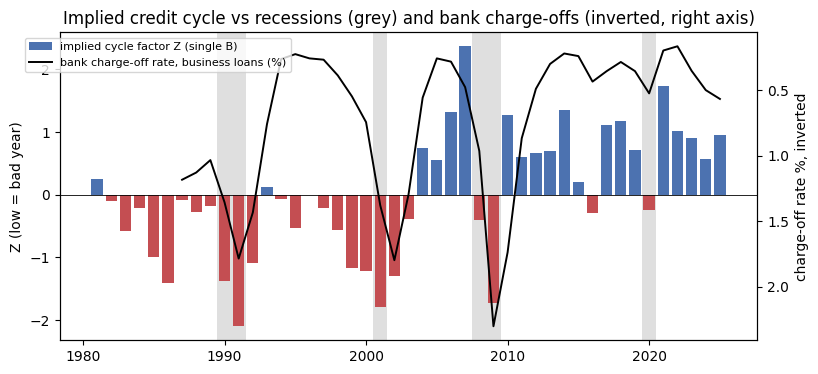

In [7]:
rec_years = macro.index[macro["USREC"] > 0]
fig, ax = plt.subplots(figsize=(9, 4))
for y in rec_years:
    ax.axvspan(y - 0.5, y + 0.5, color="grey", alpha=0.25, lw=0)
ax.bar(Z.index, Z, color=np.where(Z < 0, "#C44E52", "#4C72B0"), label="implied cycle factor Z (single B)")
ax.axhline(0, color="black", lw=0.6)
ax2 = ax.twinx()
ax2.plot(macro.index, macro["CORBLACBS"], color="black", lw=1.4, label="bank charge-off rate, business loans (%)")
ax2.invert_yaxis()
ax.set(ylabel="Z (low = bad year)", title="Implied credit cycle vs recessions (grey) and bank charge-offs (inverted, right axis)")
ax2.set_ylabel("charge-off rate %, inverted")
fig.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0.08, 0.88))
fig.savefig(ROOT / "reports" / "figures" / "implied_cycle.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the result:** the implied cycle, built only from S&P default counts, moves with independent measures of credit stress: bank charge-offs (−0.61) and delinquencies (−0.61) on business loans, and the NBER recession flag (−0.56). Two signals lead it by a year — bank delinquencies (−0.42) and the Chicago Fed financial conditions index (−0.34) — which makes them candidates for an early-warning overlay. The Baa spread moves only weakly with it (−0.27): spreads price expected risk and risk appetite, not realised defaults.

## 6. Scenario generator: base, adverse, severely adverse, 2008 replay

| Scenario | Five-year path of $Z$ |
|---|---|
| **Base** | Random AR(1) paths from the stationary distribution — what the engine simulates |
| **Adverse** | Year 1 is a 1-in-10 year ($Z_1 = \Phi^{-1}(0.10) = -1.28$); then the expected recovery $Z_t = \phi^{t-1} Z_1$ |
| **Severely adverse** | Year 1 is a 1-in-100 year ($Z_1 = -2.33$); then the expected recovery |
| **2000 replay** | Implied $\hat Z_t$ for 2000–2004 (dot-com and telecom defaults) |
| **2008 replay** | Implied $\hat Z_t$ for 2008–2012 (global financial crisis) |

For each path: the single-B default rate each year from $PD(Z_t)$, and the five-year cumulative default probability of a B issuer.

In [8]:
z1_adv, z1_sev = norm.ppf(0.10), norm.ppf(0.01)
SCEN = {"adverse": [z1_adv * PHI_ENGINE**k for k in range(5)],
        "severely adverse": [z1_sev * PHI_ENGINE**k for k in range(5)],
        "2000 replay": Z.loc[2000:2004].tolist(),
        "2008 replay": Z.loc[2008:2012].tolist()}
scen = pd.DataFrame(SCEN, index=[f"year {k}" for k in range(1, 6)]).T

rng = np.random.default_rng(3)
base = np.empty((20_000, 5))
prev = rng.standard_normal(20_000)
for k in range(5):
    base[:, k] = PHI_ENGINE * prev + np.sqrt(1 - PHI_ENGINE**2) * rng.standard_normal(20_000)
    prev = base[:, k]

def five_year_pd(path, pd_=pd_B, rho=rho_B):
    return 1 - np.prod(1 - cond_pd(pd_, rho, np.asarray(path)), axis=-1)

pd_paths = scen.apply(lambda row: pd.Series(100 * cond_pd(pd_B, rho_B, row.to_numpy()), index=row.index), axis=1)
pd_paths["5-yr cumulative B PD %"] = [100 * five_year_pd(p) for p in scen.to_numpy()]
base_cum = 100 * five_year_pd(base)
pd_paths.loc["base: average path"] = list(100 * cond_pd(pd_B, rho_B, base).mean(axis=0)) + [base_cum.mean()]
pd_paths.loc["base: worst 1 in 200 paths"] = [np.nan] * 5 + [np.quantile(base_cum, 0.995)]
print("Z paths:"); display(scen)
print("Single-B one-year default rate by year (%) and five-year cumulative PD:")
pd_paths

Z paths:


,year 1,year 2,year 3,year 4,year 5
adverse,-1.282,-0.641,-0.320,-0.160,-0.080
severely adverse,-2.326,-1.163,-0.582,-0.291,-0.145
2000 replay,-1.216,-1.785,-1.294,-0.386,0.747
2008 replay,-0.404,-1.720,1.264,0.595,0.665


Single-B one-year default rate by year (%) and five-year cumulative PD:


,year 1,year 2,year 3,year 4,year 5,5-yr cumulative B PD %
adverse,8.040,4.956,3.816,3.331,3.109,21.260
severely adverse,15.863,7.381,4.727,3.722,3.289,30.871
2000 replay,7.670,11.340,8.110,4.030,1.450,28.857
2008 replay,4.090,10.870,0.860,1.680,1.570,17.983
base: average path,3.811,3.812,3.862,3.858,3.851,17.514
base: worst 1 in 200 paths,NaN,NaN,NaN,NaN,NaN,47.954


**Reading the result:** a single bad year matters less than a run of them. The severely adverse start (1-in-100 in year 1) gives a five-year single-B default probability of 30.9%; the 2000–04 replay, with no single extreme year but three bad ones in a row, gives almost the same (28.9%). The 2008 replay is milder for corporates over five years (18.0%) because the cycle snapped back in 2010. Under random paths a B issuer defaults with 17.5% probability on average and 48% in the worst 1-in-200 path.

## 7. Save outputs

In [9]:
params = {"single_B": {"pd": float(pd_B), "rho": float(rho_B), "phi": float(phi_hat),
                       "phi_95": [float(phi_hat - 1.96 * se_phi), float(phi_hat + 1.96 * se_phi)]},
          "by_series": {k: {"pd": float(v["PD fitted %"] / 100), "rho": float(v["rho fitted"]),
                            "rho_95": [float(v["rho 95% low"]), float(v["rho 95% high"])]} for k, v in fit_table.iterrows()},
          "engine": {"phi": PHI_ENGINE, "rho_source": "Basel formula by rating (A-02)"}}
(DATA / "processed" / "cycle_parameters.yaml").write_text(yaml.safe_dump(params, sort_keys=False), encoding="utf-8")
Z.to_frame().to_parquet(DATA / "processed" / "implied_z.parquet")
scen.to_parquet(DATA / "processed" / "scenarios.parquet")
print((DATA / "processed" / "cycle_parameters.yaml").read_text()[:300])

single_B:
  pd: 0.03842738032746982
  rho: 0.12911129226084447
  phi: 0.5391381134861772
  phi_95:
  - 0.29305942275838265
  - 0.7852168042139718
by_series:
  BB:
    pd: 0.008982624628430488
    rho: 0.1107951629204497
    rho_95:
    - 0.0783872859669862
    - 0.17640585324508046
  B:
    pd: 0.03


## Validation checks

- [x] **Parameter recovery on synthetic data (V-04)** — 1,000 synthetic 45-year histories with known $PD$, $\rho$, $\phi$: the fit recovers $\rho$ without material bias and $\phi$ with the expected small-sample bias.
- [x] **Implied factor lines up with recessions** — $\hat Z_t$ is lower in every NBER recession year than the non-recession average, and correlates negatively with bank charge-offs.
- [x] **Confidence intervals for ρ and φ** — reported in sections 3 and 4; the engine's $\phi = 0.5$ and the Basel $\rho$ for single B lie inside them.

### Parameter recovery (V-04)

Generate default-rate histories from the model with known parameters — a pool of 1,000 B issuers, $PD$ = 3.5%, $\rho$ = 0.13, $\phi$ = 0.5, 45 years — then fit them exactly as the real data were fitted.

In [10]:
true = {"pd": 0.035, "rho": 0.13, "phi": 0.50}
rng = np.random.default_rng(2026)
est = []
for _ in range(1_000):
    z, prev = np.empty(45), rng.standard_normal()
    for k in range(45):
        z[k] = true["phi"] * prev + np.sqrt(1 - true["phi"]**2) * rng.standard_normal()
        prev = z[k]
    rates = rng.binomial(1_000, cond_pd(true["pd"], true["rho"], z)) / 1_000      # finite pool: binomial noise
    rates = rates[rates > 0]
    p_hat, r_hat, _ = fit_vasicek(rates)
    est.append((p_hat, r_hat, fit_phi(implied_factor(p_hat, r_hat, rates))))
est = pd.DataFrame(est, columns=["pd", "rho", "phi"])
recovery = pd.DataFrame({"true": true, "mean estimate": est.mean(), "spread (sd)": est.std(),
                         "2.5% of estimates": est.quantile(0.025), "97.5% of estimates": est.quantile(0.975)})
recovery

,true,mean estimate,spread (sd),2.5% of estimates,97.5% of estimates
pd,0.035,0.035,0.007,0.023,0.052
rho,0.130,0.129,0.029,0.079,0.191
phi,0.500,0.406,0.141,0.100,0.644


**Reading the result:** the fit recovers PD and ρ on average (3.5% and 0.129 vs 0.13 true), with the spread one would expect from 45 years. φ comes out at 0.41 on average against 0.50 true — the expected downward bias of a short autocorrelated sample, plus noise from estimating the implied factor. Read in reverse, the real-data estimate of 0.54 points to a true φ of about 0.6.

In [11]:
rec_z = z87[macro.loc[1987:2025, "USREC"] > 0]
checks = {
    "V-04: rho recovered within 0.02 on average": abs(est["rho"].mean() - true["rho"]) < 0.02,
    "V-04: PD recovered within 10% on average": abs(est["pd"].mean() / true["pd"] - 1) < 0.10,
    "V-04: phi recovered within the expected small-sample bias (< 0.10)": abs(est["phi"].mean() - true["phi"]) < 0.10,
    "Every recession year below the non-recession average Z": bool((rec_z < z87[macro.loc[1987:2025, "USREC"] == 0].mean()).all()),
    "Z correlates negatively with bank charge-offs (< -0.5)": link.loc["CORBLACBS", "same year"] < -0.5,
    "Engine phi = 0.5 inside the 95% interval": phi_hat - 1.96 * se_phi <= PHI_ENGINE <= phi_hat + 1.96 * se_phi,
    "Basel rho for single B inside the 95% interval": fit_table.loc["B", "rho 95% low"] <= fit_table.loc["B", "rho Basel"] <= fit_table.loc["B", "rho 95% high"],
}
pd.Series({k: bool(v) for k, v in checks.items()}).map({True: "PASS", False: "FAIL"})

V-04: rho recovered within 0.02 on average                            PASS
V-04: PD recovered within 10% on average                              PASS
V-04: phi recovered within the expected small-sample bias (< 0.10)    PASS
Every recession year below the non-recession average Z                PASS
Z correlates negatively with bank charge-offs (< -0.5)                PASS
Engine phi = 0.5 inside the 95% interval                              PASS
Basel rho for single B inside the 95% interval                        PASS
dtype: object

## Functions to move into the engine

| Function (this notebook) | Target module | Test |
|---|---|---|
| `cond_pd` | `creditengine.models.cycle` | Vasicek anchor (NB06, V-01) |
| `fit_vasicek` (closed-form MLE) | `creditengine.models.cycle` | parameter recovery (V-04) |
| `implied_factor` | `creditengine.models.cycle` | lines up with recessions and charge-offs |
| `fit_phi` | `creditengine.models.cycle` | parameter recovery (V-04) |
| $\chi^2$ interval for $\rho$, standard error for $\phi$ | `creditengine.models.cycle` — **new** | reported intervals |
| Scenario paths (adverse, severe, replays) | `configs/scenarios.yaml`, `simulation.portfolio` | replays equal the implied factor |

## Findings and next steps

**Key results**
- **Correlation:** single-B ρ = 0.13 (95%: 0.09–0.20); BB 0.11, CCC/C 0.12. Basel's 0.14 for B lies inside; Basel's 0.20 for BB is conservative.
- **Persistence:** φ = 0.54 (95%: 0.29–0.79); about 0.6 after small-sample bias correction. Engine uses 0.5.
- **Implied cycle:** worst years 1991, 2001, 2009; correlation −0.61 with bank charge-offs and −0.56 with recessions; bank delinquencies and financial conditions lead by a year.
- **Scenarios:** five-year single-B PD 17.5% base average, 21.3% adverse, 30.9% severely adverse, 28.9% (2000 replay), 18.0% (2008 replay).
- **Recovery test:** ρ and PD unbiased on synthetic data; φ biased down by about 0.09.

**Assumptions** (record in `docs/assumption_register.md`)
- A-02 unchanged: ρ from the Basel formula by rating; supported for B, conservative for BB.
- A-03: φ = 0.5 kept for v0.2; the data point to 0.54 (0.6 bias-corrected) — candidate to raise to 0.6 in v0.3.
- Added: scenario definitions (adverse 1-in-10, severely adverse 1-in-100 with expected recovery; 2000 and 2008 replays).

**Limitations** (record in `docs/limitations.md`)
1. **Short history:** 45 annual points give wide intervals for ρ and φ.
2. **One factor:** a single global cycle; sector and regional cycles are only a sensitivity (NB06).
3. **Global data, US book:** the S&P series is global; the US cycle may be more pronounced.
4. **Zero-default years:** investment-grade ratings cannot be fitted this way, so their ρ comes from Basel.
5. **Implied factor from one rating:** using single B ties the cycle to the speculative-grade market.

**Next:** NB05 (recovery and LGD linked to the cycle), then NB09 (capital, pricing and limits).